# Laboratorium 1: Analiza statystyczna i wizualizacja w Pythonie

Ten notatnik demonstruje kluczowe pojęcia statystyczne przy użyciu danych sztucznych (ponad 200 obserwacji). Każda sekcja zawiera wyjaśnienia, kod w Pythonie i wizualizacje dla:

- Średnia, Mediana, Dominanta
- Skośność, Dominanta, Kwartyle
- Wariancja, Odchylenie standardowe
- Testowanie hipotez
- Prawo wielkich liczb

Wszystkie przykłady używają losowo wygenerowanych danych do zilustrowania pojęć.

In [ ]:
# Import libraries and generate artificial data
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Set random seed for reproducibility
np.random.seed(42)

# Generate artificial data (normal distribution, 20000 observations)
data = np.random.normal(loc=50, scale=10, size=20000)
df = pd.DataFrame({'Value': data})
df.describe()

,Value
count,20000.000000
mean,50.056990
std,10.022426
min,10.775997
25%,43.337232
50%,50.077005
75%,56.819069
max,94.790843


## Miary tendencji centralnej

Tendencja centralna opisuje środek zbioru danych. Najczęściej stosowane miary to:
- **Średnia**: Wartość przeciętna
- **Mediana**: Wartość środkowa po posortowaniu danych
- **Dominanta (moda)**: Najczęściej występująca wartość
- **Dominanta**: Czasami używana jako synonim mody

Mean: 50.06
Median: 50.08
Mode: 10.78


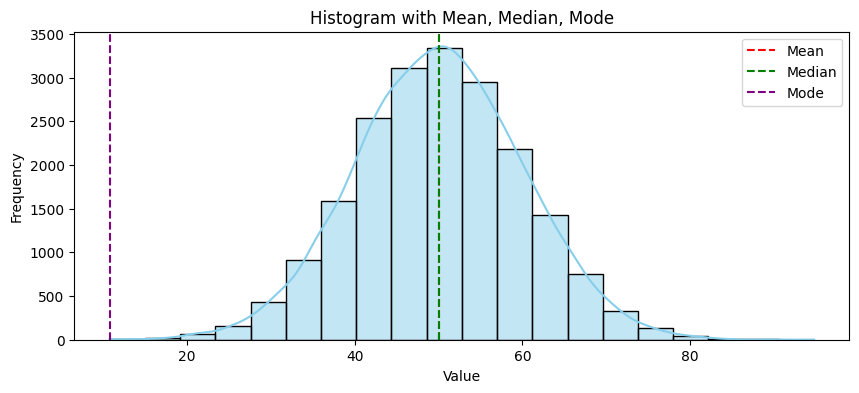

In [ ]:
# Calculate mean, median, mode, and dominant
mean = df['Value'].mean()
median = df['Value'].median()
mode = df['Value'].mode()[0]
dominant = mode  # For this example, dominant = mode

print(f"Mean: {mean:.2f}")
print(f"Median: {median:.2f}")
print(f"Mode: {mode:.2f}")

# Visualize with histogram
plt.figure(figsize=(10,4))
sns.histplot(df['Value'], bins=20, kde=True, color='skyblue')
plt.axvline(mean, color='red', linestyle='--', label='Mean')
plt.axvline(median, color='green', linestyle='--', label='Median')
plt.axvline(mode, color='purple', linestyle='--', label='Mode')
plt.legend()
plt.title('Histogram with Mean, Median, Mode')
plt.xlabel('Value')
plt.ylabel('Frequency')
plt.show()

## Miary rozproszenia

Rozproszenie opisuje, jak rozproszone są dane. Do popularnych miar należą:
- **Wariancja**: Średnia z kwadratów odchyleń od średniej
- **Odchylenie standardowe**: Pierwiastek z wariancji, pokazuje rozrzut w oryginalnych jednostkach
- **Kwartyle**: Wartości dzielące dane na cztery równe części

Variance: 100.45
Standard Deviation: 10.02
Quartiles:
0.25    43.337232
0.50    50.077005
0.75    56.819069
Name: Value, dtype: float64


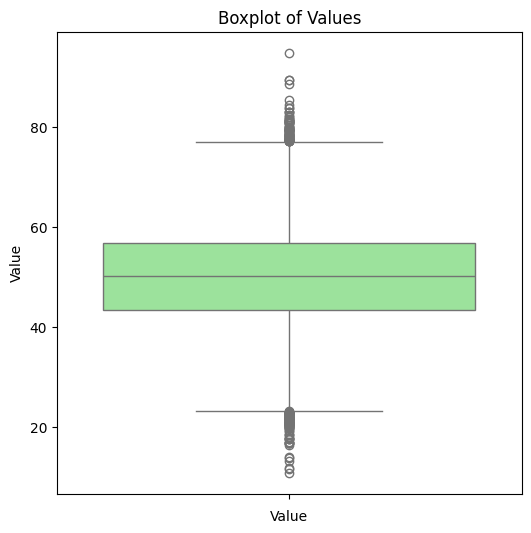

In [ ]:
# Calculate variance, standard deviation, quartiles
import logging

variance = df['Value'].var()
std_dev = df['Value'].std()
quartiles = df['Value'].quantile([0.25, 0.5, 0.75])

print(f"Variance: {variance:.2f}")
print(f"Standard Deviation: {std_dev:.2f}")
print("Quartiles:")
print(quartiles)

# Visualize with boxplot
plt.figure(figsize=(6,6))
sns.boxplot(df['Value'], color='lightgreen')
plt.title('Boxplot of Values')
plt.xlabel('Value')
plt.show()

## Skośność

Skośność mierzy asymetrię rozkładu danych:
- **Dodatnia skośność**: Ogon po prawej stronie
- **Ujemna skośność**: Ogon po lewej stronie
- **Brak skośności**: Rozkład symetryczny

Skewness: -0.00


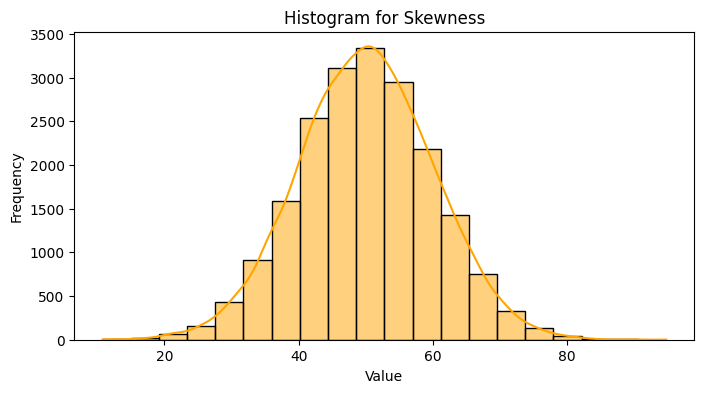

In [ ]:
# Calculate skewness
skewness = stats.skew(df['Value'])
print(f"Skewness: {skewness:.2f}")

# Visualize skewness, KDE smooth density curve
plt.figure(figsize=(8,4))
sns.histplot(df['Value'], bins=20, kde=True, color='orange')
plt.title('Histogram for Skewness')
plt.xlabel('Value')
plt.ylabel('Frequency')
plt.show()

## Testowanie hipotez

Testowanie hipotez służy do ustalenia, czy istnieje wystarczająco dużo dowodów wspierających twierdzenie o populacji. Typowe kroki:
- Sformułuj hipotezę zerową i alternatywną
- Wybierz poziom istotności (alpha)
- Oblicz statystykę testu i wartość p
- Wyciągnij wniosek

## Test t i wartość p (wyjaśnienie)

Test t (test Studenta) służy do porównywania średnich i oceny, czy obserwowana różnica jest istotna statystycznie. Podstawowe informacje:
- **Statystyka t**: miara różnicy między średnią próbki a wartością oczekiwaną (hipotezą zerową), wyrażona w jednostkach błędu standardowego.
- **Wartość p**: prawdopodobieństwo otrzymania statystyki co najmniej tak ekstremalnej jak obserwowana, zakładając, że hipoteza zerowa jest prawdziwa. Mała wartość p (np. < 0.05) wskazuje, że zaobserwowana różnica jest mało prawdopodobna przy hipotezie zerowej.

Poniższy kod rysuje rozkład t (dla odpowiednich stopni swobody), zaznacza obserwowaną statystykę t i zacienia obszary odpowiadające dwustronnej wartości p. Dodatkowo pokazany jest przykład z rzeczywistego świata (porównanie ciśnienia między dwiema grupami).

/tmp/ipykernel_454/4113411830.py:37: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


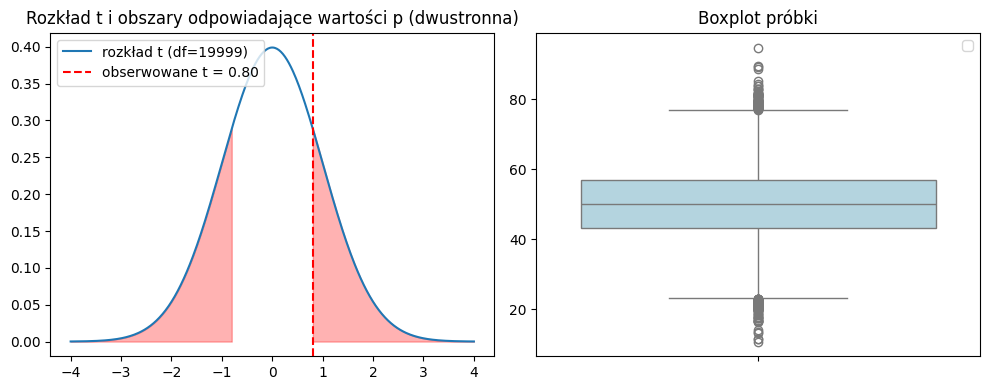

Obserwowana statystyka t: 0.804, dwustronna wartość p: 0.4213
Przykład: porównanie ciśnienia (kontrola vs leczenie) — t = 2.438, p = 0.0167


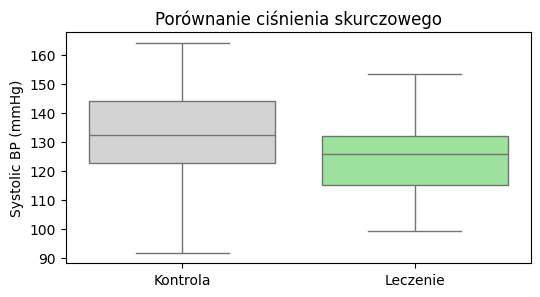

In [ ]:
# Wizualizacja rozkładu t i przykład rzeczywisty (po polsku)
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Użyj istniejącej próbki z notatnika
sample = df['Value'].values
n = len(sample)
t_stat, p_value = stats.ttest_1samp(sample, 50)
df_t = n - 1

# Rozkład t dla df = n-1
from scipy.stats import t as tdist
x = np.linspace(-4, 4, 400)
y = tdist.pdf(x, df_t)

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(x, y, label=f'rozkład t (df={df_t})')
obs = t_stat
plt.axvline(obs, color='red', linestyle='--', label=f'obserwowane t = {obs:.2f}')
# Zaciemnienie obszarów odpowiadających dwustronnej wartości p
crit = abs(obs)
xs = np.linspace(crit, 4, 200)
plt.fill_between(xs, tdist.pdf(xs, df_t), color='red', alpha=0.3)
xs = np.linspace(-4, -crit, 200)
plt.fill_between(xs, tdist.pdf(xs, df_t), color='red', alpha=0.3)
plt.title('Rozkład t i obszary odpowiadające wartości p (dwustronna)')
plt.legend()

# Boxplot próbki z linią hipotezy
plt.subplot(1,2,2)
sns.boxplot(sample, color='lightblue')
# plt.axvline(50, color='red', linestyle='--', label='Hipoteza: średnia = 50')
plt.title('Boxplot próbki')
plt.legend()
plt.tight_layout()
plt.show()

print(f'Obserwowana statystyka t: {t_stat:.3f}, dwustronna wartość p: {p_value:.4f}')

# Przykład z rzeczywistego świata: porównanie ciśnienia skurczowego między grupą kontrolną i leczoną
np.random.seed(0)
n = 50
control = np.random.normal(loc=130, scale=15, size=n)
treatment = np.random.normal(loc=125, scale=15, size=n)  # np. efekt leczenia obniżającego ciśnienie
t_real, p_real = stats.ttest_ind(control, treatment, equal_var=False)
print(f'Przykład: porównanie ciśnienia (kontrola vs leczenie) — t = {t_real:.3f}, p = {p_real:.4f}')

# Wykres dla przykładu rzeczywistego
plt.figure(figsize=(6,3))
sns.boxplot([control, treatment], palette=['lightgrey','lightgreen'])
plt.xticks([0,1], ['Kontrola','Leczenie'])
plt.title('Porównanie ciśnienia skurczowego')
plt.ylabel('Systolic BP (mmHg)')
plt.show()

t-statistic: 0.80
p-value: 0.4213
Fail to reject the null hypothesis: Mean is not significantly different from 50.


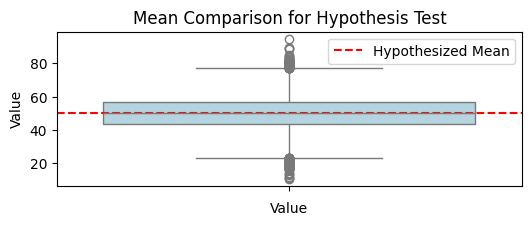

In [ ]:
# One-sample t-test: Is the mean significantly different from 50?
t_stat, p_value = stats.ttest_1samp(df['Value'], 50)
print(f"t-statistic: {t_stat:.2f}")
print(f"p-value: {p_value:.4f}")

if p_value < 0.05:
    print("Reject the null hypothesis: Mean is significantly different from 50.")
else:
    print("Fail to reject the null hypothesis: Mean is not significantly different from 50.")

# Visualize mean comparison
plt.figure(figsize=(6,2))
sns.boxplot(df['Value'], color='lightblue')
plt.axhline(50, color='red', linestyle='--', label='Hypothesized Mean')
plt.legend()
plt.title('Mean Comparison for Hypothesis Test')
plt.xlabel('Value')
plt.show()

## Przykład: wartość p < 0.05 i statystyka t > 1.96

Poniżej pokazany jest przykład, w którym statystyka t przekracza 1.96, a dwustronna wartość p jest mniejsza niż 0.05. Wartości ±1.96 pochodzą z rozkładu normalnego (Z): dla jednostajnego rozkładu normalnego standaryzowanego P(|Z| > 1.96) = 0.05, czyli obszar krytyczny dla poziomu istotności 5% (dwustronnie).
Dla dużych stopni swobody rozkład t zbiega do rozkładu normalnego, dlatego krytyczne wartości dla t są bliskie ±1.96.


Obserwowana statystyka t: 2.335
Dwustronna wartość p: 0.0230
Czy t > 1.96? True
Czy p < 0.05? True


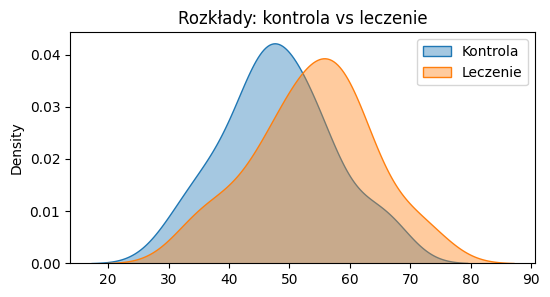

Krytyczna wartość Z dla poziomu 0.05 (dwustronnie): 1.960


In [ ]:
# Stwórz przykład, gdzie różnica średnich daje t > 1.96 i p < 0.05
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)
n = 30
# kontrola i leczenie z różnicą średnich = 6, sd = 10 -> oczekiwane t około 2.3
control = np.random.normal(loc=50, scale=10, size=n)
treatment = control + 6 + np.random.normal(loc=0, scale=3, size=n)
t_stat, p_val = stats.ttest_ind(treatment, control, equal_var=False)
print(f'Obserwowana statystyka t: {t_stat:.3f}')
print(f'Dwustronna wartość p: {p_val:.4f}')

# Sprawdź warunki: czy t > 1.96 i p < 0.05?
print('Czy t > 1.96?', t_stat > 1.96)
print('Czy p < 0.05?', p_val < 0.05)

# Wykres rozkładów i zaznaczenie różnicy
plt.figure(figsize=(6,3))
sns.kdeplot(control, label='Kontrola', fill=True, alpha=0.4)
sns.kdeplot(treatment, label='Leczenie', fill=True, alpha=0.4)
plt.title('Rozkłady: kontrola vs leczenie')
plt.legend()
plt.show()

# Dodatkowe wyjaśnienie: krytyczna wartość ±1.96 (dla Z) oznacza obszar odcięcia 2.5% po obu stronach rozkładu
from scipy.stats import norm
z_crit = norm.ppf(0.975)
print(f'Krytyczna wartość Z dla poziomu 0.05 (dwustronnie): {z_crit:.3f}')

## Prawo wielkich liczb

Prawo wielkich liczb mówi, że wraz ze wzrostem rozmiaru próby średnia próbki zbliża się do średniej populacji. Ta zasada jest fundamentalna w statystyce i rachunku prawdopodobieństwa.

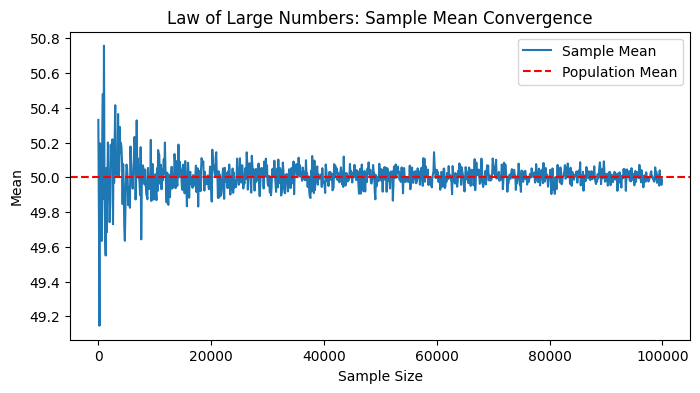

In [ ]:
# Demonstrate law of large numbers
sample_sizes = np.arange(10, 100001, 100)
sample_means = [np.random.normal(loc=50, scale=10, size=n).mean() for n in sample_sizes]

plt.figure(figsize=(8,4))
plt.plot(sample_sizes, sample_means, label='Sample Mean')
plt.axhline(50, color='red', linestyle='--', label='Population Mean')
plt.title('Law of Large Numbers: Sample Mean Convergence')
plt.xlabel('Sample Size')
plt.ylabel('Mean')
plt.legend()
plt.show()